<a href="https://colab.research.google.com/github/qtrong0205/plant-care-ai-service/blob/main/classification/training/train_plant_disease_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Plant Care - Classification

In [1]:
!git clone https://github.com/qtrong0205/plant-care-ai-service
%cd plant-care-ai-service/classification/training

Cloning into 'plant-care-ai-service'...
remote: Enumerating objects: 11, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 11 (delta 0), reused 11 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (11/11), done.
/content/plant-care-ai-service/classification/training


## 1. Problem Definition

- 1.1. Objective

  The objective of this project is to build a deep learning model that automatically classifies plant diseases from leaf images. The trained model will be deployed as an **ONNX model** in a FastAPI service to provide real-time disease diagnosis for the Plant Care Assistant application.

- 1.2. Dataset

  The model is trained on the **PlantVillage** dataset, which contains approximately 54,000 images across 38 classes covering 14 plant species and their disease categories. To accelerate experimentation and hyperparameter tuning, the initial training will use only 20% of the training dataset (approximately 10,000 images). After selecting the best configuration, the final model will be trained on the full dataset.

- 1.3. Evaluation Metrics

  Model performance will be evaluated using Accuracy, Precision, Recall, F1-score, and the Confusion Matrix.

## 2. Import libraries and Setup device agnostic code

In [25]:
import os
import torch
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

In [3]:
# Device agnostic code
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cpu'

## 3. Load & Explore Data



### 3.1. Download and unzip data

In [11]:
from pathlib import Path

DATA_DIR = Path("data/plantvillage dataset/color")

if DATA_DIR.exists() and any(DATA_DIR.iterdir()):
    print(f"Dataset already exist at '{DATA_DIR}', download skipped.")
else:
    print("Downloading data from Kaggle...")
    !kaggle datasets download -d abdallahalidev/plantvillage-dataset
    !unzip -q plantvillage-dataset.zip -d data/
    print("Downloaded and unziped.")

Dataset already exist at 'data/plantvillage dataset/color', download skipped.


In [21]:
from split_dataset import split_dataset

SPLIT_PATH = Path("data/split")
train_path = Path("data/split/train")
test_path = Path("data/split/test")

if train_path.exists() and test_path.exists() and len(list(train_path.iterdir())) == 38:
    print("Already splitted")
else:
    split_dataset(
        source_dir="data/plantvillage dataset/color",
        output_dir=SPLIT_PATH,
        train_ratio=0.8,
    )

Already splitted


### 3.2. Create a Custom `ImageDataset` Class

In this section, we implement a custom `ImageDataset` class that accepts the dataset directory, image transformations, and a subset ratio. The `subset_ratio` parameter allows loading only a specified percentage of the original dataset, enabling faster experimentation and model training.

The implementation of the `ImageDataset` class is available in the project repository:

> **GitHub:** https://github.com/qtrong0205/plant-care-ai-service/blob/main/classification/training/data_setup.py

In [14]:
from data_setup import ImageDataset

# Create a dataset with custom ImageDataset
train_dataset = ImageDataset(
    targ_dir=train_path,
    transform=None,
    subset_ratio=0.2,
    seed=42,
)
test_dataset = ImageDataset(
    targ_dir=test_path,
    transform=None,
    subset_ratio=0.2,
    seed=42,
)

print(f"Number of classes in train dataset: {len(train_dataset.classes)}")
print(f"Number of images in train dataset: {len(train_dataset)}")
print(f"Number of classes in test dataset: {len(test_dataset.classes)}")
print(f"Number of images in test dataset: {len(test_dataset)}")

Number of classes in train dataset: 38
Number of images in train dataset: 8673
Number of classes in test dataset: 38
Number of images in test dataset: 2165


### 3.3. Visualize an image

In [22]:
SPLIT_PATH

PosixPath('data/split')

In [20]:
DATA_DIR

PosixPath('data/plantvillage dataset/color')

Random image path: data/split/train/Tomato___Late_blight/c3a5ec63-9d0d-48a2-898a-9bc31b4443a9___GHLB_PS Leaf 1.2 Day 16.jpg
Image class: Tomato___Late_blight
Image height: 256
Image width: 256


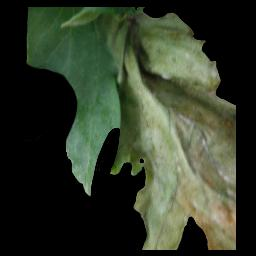

In [33]:
import random
from PIL import Image

# Set seed
# random.seed(42)

# 1. Get all image paths (* means "any combination")
image_path_list = list(SPLIT_PATH.glob("*/*/*.jpg"))

# 2. Get random image path
random_image_path = random.choice(image_path_list)

# 3. Get image class from path name (the image class is the name of the directory where the image is stored)
image_class = random_image_path.parent.stem

# 4. Open image
img = Image.open(random_image_path)

# 5. Print metadata
print(f"Random image path: {random_image_path}")
print(f"Image class: {image_class}")
print(f"Image height: {img.height}")
print(f"Image width: {img.width}")
img

(np.float64(-0.5), np.float64(255.5), np.float64(255.5), np.float64(-0.5))

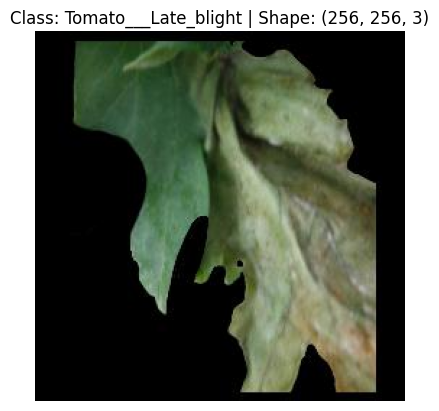

In [35]:
# Turn image into numpy array
img_as_array = np.asarray(img)

plt.imshow(img_as_array)
plt.title(f"Class: {image_class} | Shape: {img_as_array.shape}")
plt.axis(False)